<a href="https://colab.research.google.com/github/vedrode2011-collab/TFIM-trotter-experiment/blob/main/ZX_Reduction_Quantum_Adder.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Quantum Adder Circuit: ZX-Calculus Reduction, Equivalence Checking, and Noisy-Hardware Magnetization Accuracy Comparison

In [ ]:
!pip install qiskit qiskit_aer qiskit-ibm-runtime pyzx pylatexenc

In [5]:
import numpy as np
from datetime import datetime

import matplotlib.pyplot as plt
import pyzx as zx
from qiskit import QuantumCircuit, qasm2
from qiskit.quantum_info import Operator, Statevector, Pauli
from qiskit.transpiler import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService, SamplerV2 as Sampler
from qiskit_ibm_runtime.fake_provider import FakeKingston
from qiskit.visualization import plot_histogram
from IPython.display import display
from qiskit import QuantumCircuit, QuantumRegister, ClassicalRegister

## 1. Build the Quantum Adder circuit (baseline)

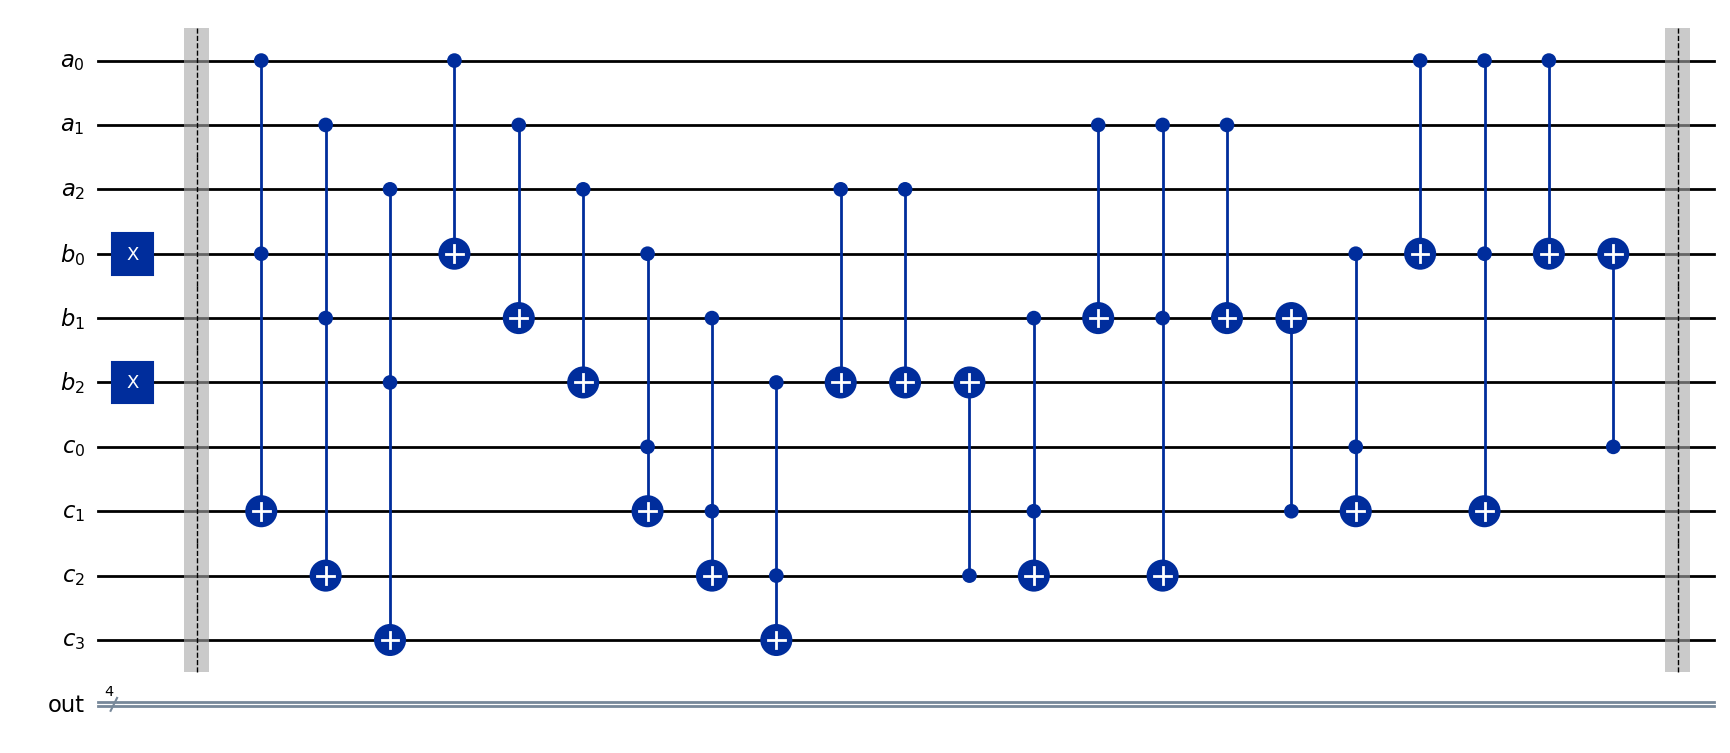

In [6]:
def quantum_adder(a_str, b_str):
    # Pad to equal length
    n = max(len(a_str), len(b_str))
    a_str, b_str = a_str.zfill(n), b_str.zfill(n)

    a = QuantumRegister(n, 'a')
    b = QuantumRegister(n, 'b')        # will hold the sum
    c = QuantumRegister(n + 1, 'c')    # carries (c[n] = final carry-out)
    out = ClassicalRegister(n + 1, 'out')
    qc = QuantumCircuit(a, b, c, out)

    # Load inputs (string's last char = least significant bit = qubit 0)
    for i, bit in enumerate(reversed(a_str)):
        if bit == '1': qc.x(a[i])
    for i, bit in enumerate(reversed(b_str)):
        if bit == '1': qc.x(b[i])
    qc.barrier()

    def carry(i):
        qc.ccx(a[i], b[i], c[i + 1])
        qc.cx(a[i], b[i])
        qc.ccx(c[i], b[i], c[i + 1])

    def carry_inv(i):
        qc.ccx(c[i], b[i], c[i + 1])
        qc.cx(a[i], b[i])
        qc.ccx(a[i], b[i], c[i + 1])

    def sum_(i):
        qc.cx(a[i], b[i])
        qc.cx(c[i], b[i])

    # Ripple-carry adder (Vedral-Barenco-Ekert)
    for i in range(n):
        carry(i)
    qc.cx(a[n - 1], b[n - 1])
    sum_(n - 1)
    for i in range(n - 2, -1, -1):
        carry_inv(i)
        sum_(i)
    qc.barrier()
    return qc

A, B = "00", "101" # try diff bit strings
qc_baseline = quantum_adder(A, B)
qc_baseline.draw('mpl')

## 2. Reduction functions

Each function does: `qc -> qasm -> pyzx graph -> reduce -> extract -> qasm -> qc`,
then checks equivalence against the baseline circuit before returning.
Raises immediately if the check fails.

The extractor differs by reduction type:
- `teleport_reduce` leaves the graph CIRCUIT-LIKE, so it converts back directly via `zx.Circuit.from_graph()`.
- `full_reduce` changes the graph into a general GRAPH-LIKE ZX-diagram (only green spiders plus Hadamard edges),
  which requires the special `zx.extract_circuit()` method to convert back into a circuit.

Using the wrong one raises an error.

In [7]:
def clean_for_zx(qc):
    """Copy of qc with only the quantum gates: no classical bits, no barriers."""
    clean = QuantumCircuit(*qc.qregs)
    for inst in qc.data:
        if inst.operation.name != "barrier":
            clean.append(inst.operation, inst.qubits)
    return clean


def teleport_reduce_circuit(qc):
    qasm_str = qasm2.dumps(clean_for_zx(qc))
    zx_baseline = zx.Circuit.from_qasm(qasm_str)
    graph = zx_baseline.to_graph()
    zx.teleport_reduce(graph)
    extracted = zx.Circuit.from_graph(graph)

    if not zx_baseline.verify_equality(extracted):
        raise ValueError("teleport_reduce output is NOT equal to baseline circuit")

    return QuantumCircuit.from_qasm_str(extracted.to_qasm())


def full_reduce_circuit(qc):
    qasm_str = qasm2.dumps(clean_for_zx(qc))
    zx_baseline = zx.Circuit.from_qasm(qasm_str)
    graph = zx_baseline.to_graph()
    zx.full_reduce(graph)
    extracted = zx.extract_circuit(graph.copy())

    if not zx_baseline.verify_equality(extracted):
        raise ValueError("full_reduce output is NOT equal to baseline circuit")

    return QuantumCircuit.from_qasm_str(extracted.to_qasm())


# Run the two reductions, each checked against the baseline as it's produced
qc_careful = teleport_reduce_circuit(qc_baseline)
print("teleport_reduce: equivalence check passed.")

qc_aggressive = full_reduce_circuit(qc_baseline)
print("full_reduce: equivalence check passed.")

teleport_reduce: equivalence check passed.
full_reduce: equivalence check passed.


## 3. Pre-flight metrics (before running anything)\n\nTotal gates, two-qubit gates, T-count, depth — for all three versions.

In [8]:
def circuit_metrics(qc):
    qc = clean_for_zx(qc)          # drops barriers/classical bits so all versions are counted fairly
    ops = qc.count_ops()
    total_gates = sum(ops.values())
    two_qubit_gates = sum(v for k, v in ops.items() if k in ("cx", "cz", "swap", "ecr"))

    # T-count via the ZX-graph representation (counts non-Clifford phase spiders)
    qasm_str = qasm2.dumps(qc)
    graph = zx.Circuit.from_qasm(qasm_str).to_graph()
    tcount = zx.tcount(graph)

    return {
        "total_gates": total_gates,
        "two_qubit_gates": two_qubit_gates,
        "tcount": tcount,
        "depth": qc.depth(),
    }

versions = {
    "baseline": qc_baseline,
    "careful": qc_careful,
    "aggressive": qc_aggressive,
}

print("--- Pre-flight circuit metrics ---")
for name, circ in versions.items():
    m = circuit_metrics(circ)
    print(name, "total_gates=", m["total_gates"], "two_qubit_gates=", m["two_qubit_gates"],
          "tcount=", m["tcount"], "depth=", m["depth"])

--- Pre-flight circuit metrics ---
baseline total_gates= 24 two_qubit_gates= 12 tcount= 70 depth= 19
careful total_gates= 164 two_qubit_gates= 72 tcount= 70 depth= 87
aggressive total_gates= 154 two_qubit_gates= 67 tcount= 24 depth= 85


## 4. Backend setup

One switch controls everything downstream: `backend_mode` is either `"fake"` or `"real"`.
This replaces the old separate scratch section (which referenced an undefined `ManilaV2()`,
and was later pinned to the now-retired `ibm_manila`) with a single, consistent path.
The real backend is pinned by name to `ibm_kingston`
(not "least busy") so results stay directly comparable to `FakeKingston` run after run.

In [9]:
# Choose which backend to run on: "fake" or "real"
backend_mode = "fake"   # switch to "real" once validated

if backend_mode == "fake":
    backend = FakeKingston()
else:
    service = QiskitRuntimeService()
    backend = service.backend("ibm_kingston")   # pinned by name, not least_busy

print(f"Using backend: {backend.name} (mode={backend_mode})")

pm = generate_preset_pass_manager(optimization_level=1, backend=backend)

shots_per_run = 4000
num_repetitions = 3

Using backend: fake_kingston (mode=fake)


## 5. Reusable function: run a set of circuits on a given backend

Same code path for fake and real hardware. Each circuit (baseline, careful, aggressive)
is transpiled specifically for the target backend's native gate set — this is the
"different hardware speaks a different language" step — then run, with counts and
pre-flight metrics stored together.

In [10]:
def run_versions_on_backend(versions, backend, shots=4000):
    pm_local = generate_preset_pass_manager(optimization_level=1, backend=backend)
    sampler = Sampler(mode=backend)
    results = {}

    for name, circ in versions.items():
        circ_with_measurement = circ.copy()
        circ_with_measurement.measure_all()
        isa_circ = pm_local.run(circ_with_measurement)

        job = sampler.run([isa_circ], shots=shots)
        counts = job.result()[0].data.meas.get_counts()

        ops = isa_circ.count_ops()
        results[name] = {
            "counts": counts,
            "job_id": job.job_id(),
            "metrics": {
                "total_gates": sum(ops.values()),
                "two_qubit_gates": sum(v for k, v in ops.items() if k in ("cz", "cx", "ecr", "swap")),
                "depth": isa_circ.depth(),
            },

        }
    return results

## 6. Run baseline, careful, and aggressive on BOTH the fake and the real Kingston backend\n\nUsing the identical function for both, so the comparison is apples-to-apples.

In [11]:
REAL_MODE = "off"      # "off"     -> never touch IBM
                       # "submit"  -> run on IBM ONCE, print job IDs to save
                       # "restore" -> load from saved_job_ids (free, no new jobs)

# After a "submit" run, paste the printed line(s) here, then use "restore".
saved_job_ids = {
    # "n3": {"baseline": "...", "careful": "...", "aggressive": "..."},
}

_real_cache = {}   # never run the same circuit set twice in one session
_service = None

def _get_service():
    global _service
    if _service is None:
        _service = QiskitRuntimeService()
    return _service


def retrieve_results_from_job_ids(job_ids, versions_x):
    svc = _get_service()
    results = {}
    for name, jid in job_ids.items():
        counts = svc.job(jid).result()[0].data.meas.get_counts()
        results[name] = {
            "counts": counts,
            "job_id": jid,
            "metrics": circuit_metrics(versions_x[name]),
        }
    return results


def submit_real(versions_x, tag):
    """Submit all versions to IBM, print the job IDs BEFORE waiting, then collect results."""
    backend_real = _get_service().backend("ibm_kingston")
    pm_real = generate_preset_pass_manager(optimization_level=1, backend=backend_real)
    sampler = Sampler(mode=backend_real)
    jobs = {}
    for name, circ in versions_x.items():
        c = circ.copy()
        c.measure_all()
        jobs[name] = sampler.run([pm_real.run(c)], shots=shots_per_run)
    ids = {n: j.job_id() for n, j in jobs.items()}
    print(f'SAVE THIS NOW -> saved_job_ids["{tag}"] = {ids}')
    saved_job_ids[tag] = ids            # in-memory too, so it can't be resubmitted
    return retrieve_results_from_job_ids(ids, versions_x)


def get_real_results(versions_x, tag):
    """Returns real-hardware results for this circuit set, or None."""
    if REAL_MODE == "off":
        return None
    if tag in _real_cache:
        return _real_cache[tag]
    if tag in saved_job_ids:                       # have IDs -> never resubmit
        res = retrieve_results_from_job_ids(saved_job_ids[tag], versions_x)
    elif REAL_MODE == "submit":
        res = submit_real(versions_x, tag)
    else:                                          # "restore" but no IDs for this size
        print(f'[restore] no saved job IDs for "{tag}" -- skipping real results for it')
        return None
    _real_cache[tag] = res
    return res


fake_backend = FakeKingston()
fake_results = run_versions_on_backend(versions, fake_backend, shots=shots_per_run)
real_results = get_real_results(versions, "n3")    # the 3-bit adder (10 qubits); None if REAL_MODE == "off"

## 7. Histograms: fake vs. real, for all three circuit versions

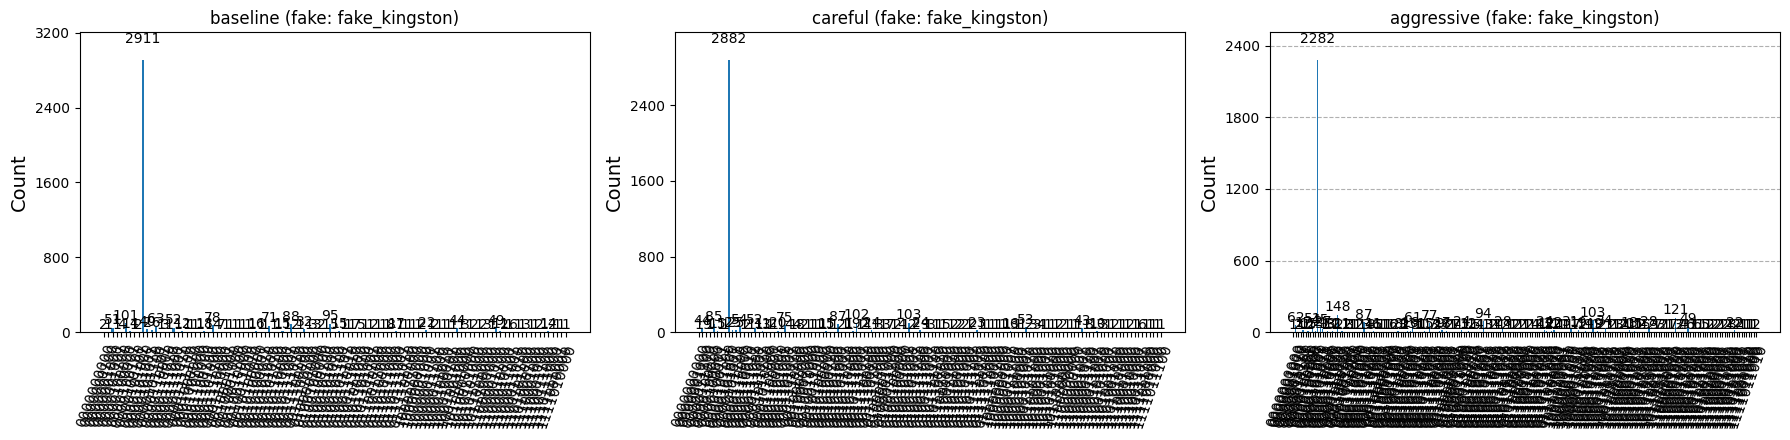

In [12]:
rows = 2 if real_results is not None else 1
fig, axes = plt.subplots(rows, 3, figsize=(18, 4.5 * rows), squeeze=False)

for col, name in enumerate(versions):
    plot_histogram(fake_results[name]["counts"], ax=axes[0][col])
    axes[0][col].set_title(f"{name} (fake: {fake_backend.name})")
    if real_results is not None:
        plot_histogram(real_results[name]["counts"], ax=axes[1][col])
        axes[1][col].set_title(f"{name} (real: ibm_kingston)")

plt.tight_layout()
plt.show()

## 8. The Circuits of all 3: Baseline, teleport_reduce, and full_reduce

Baseline circuit:


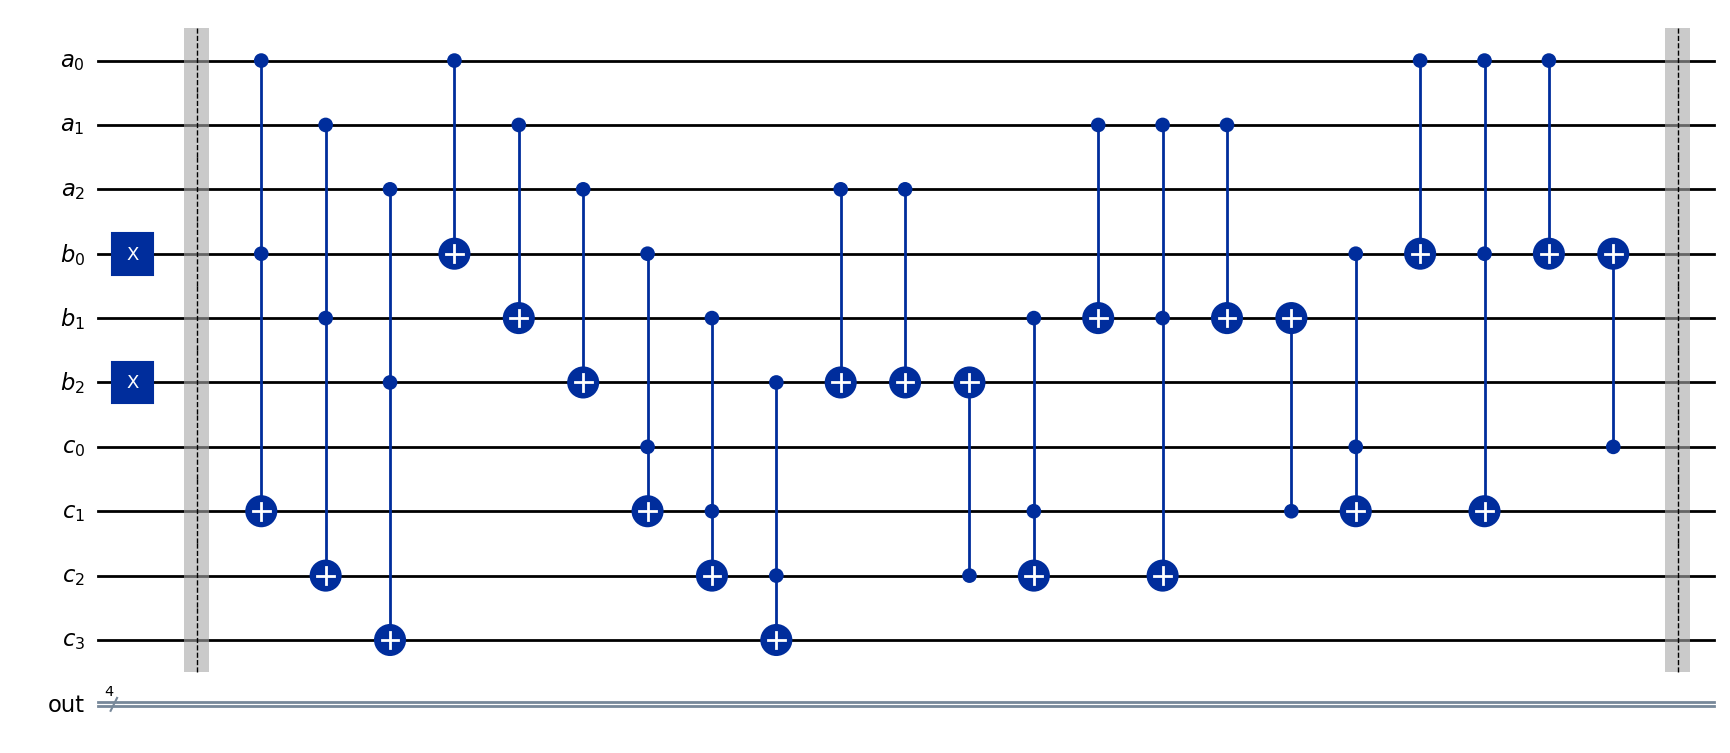

Careful (teleport_reduce) circuit:


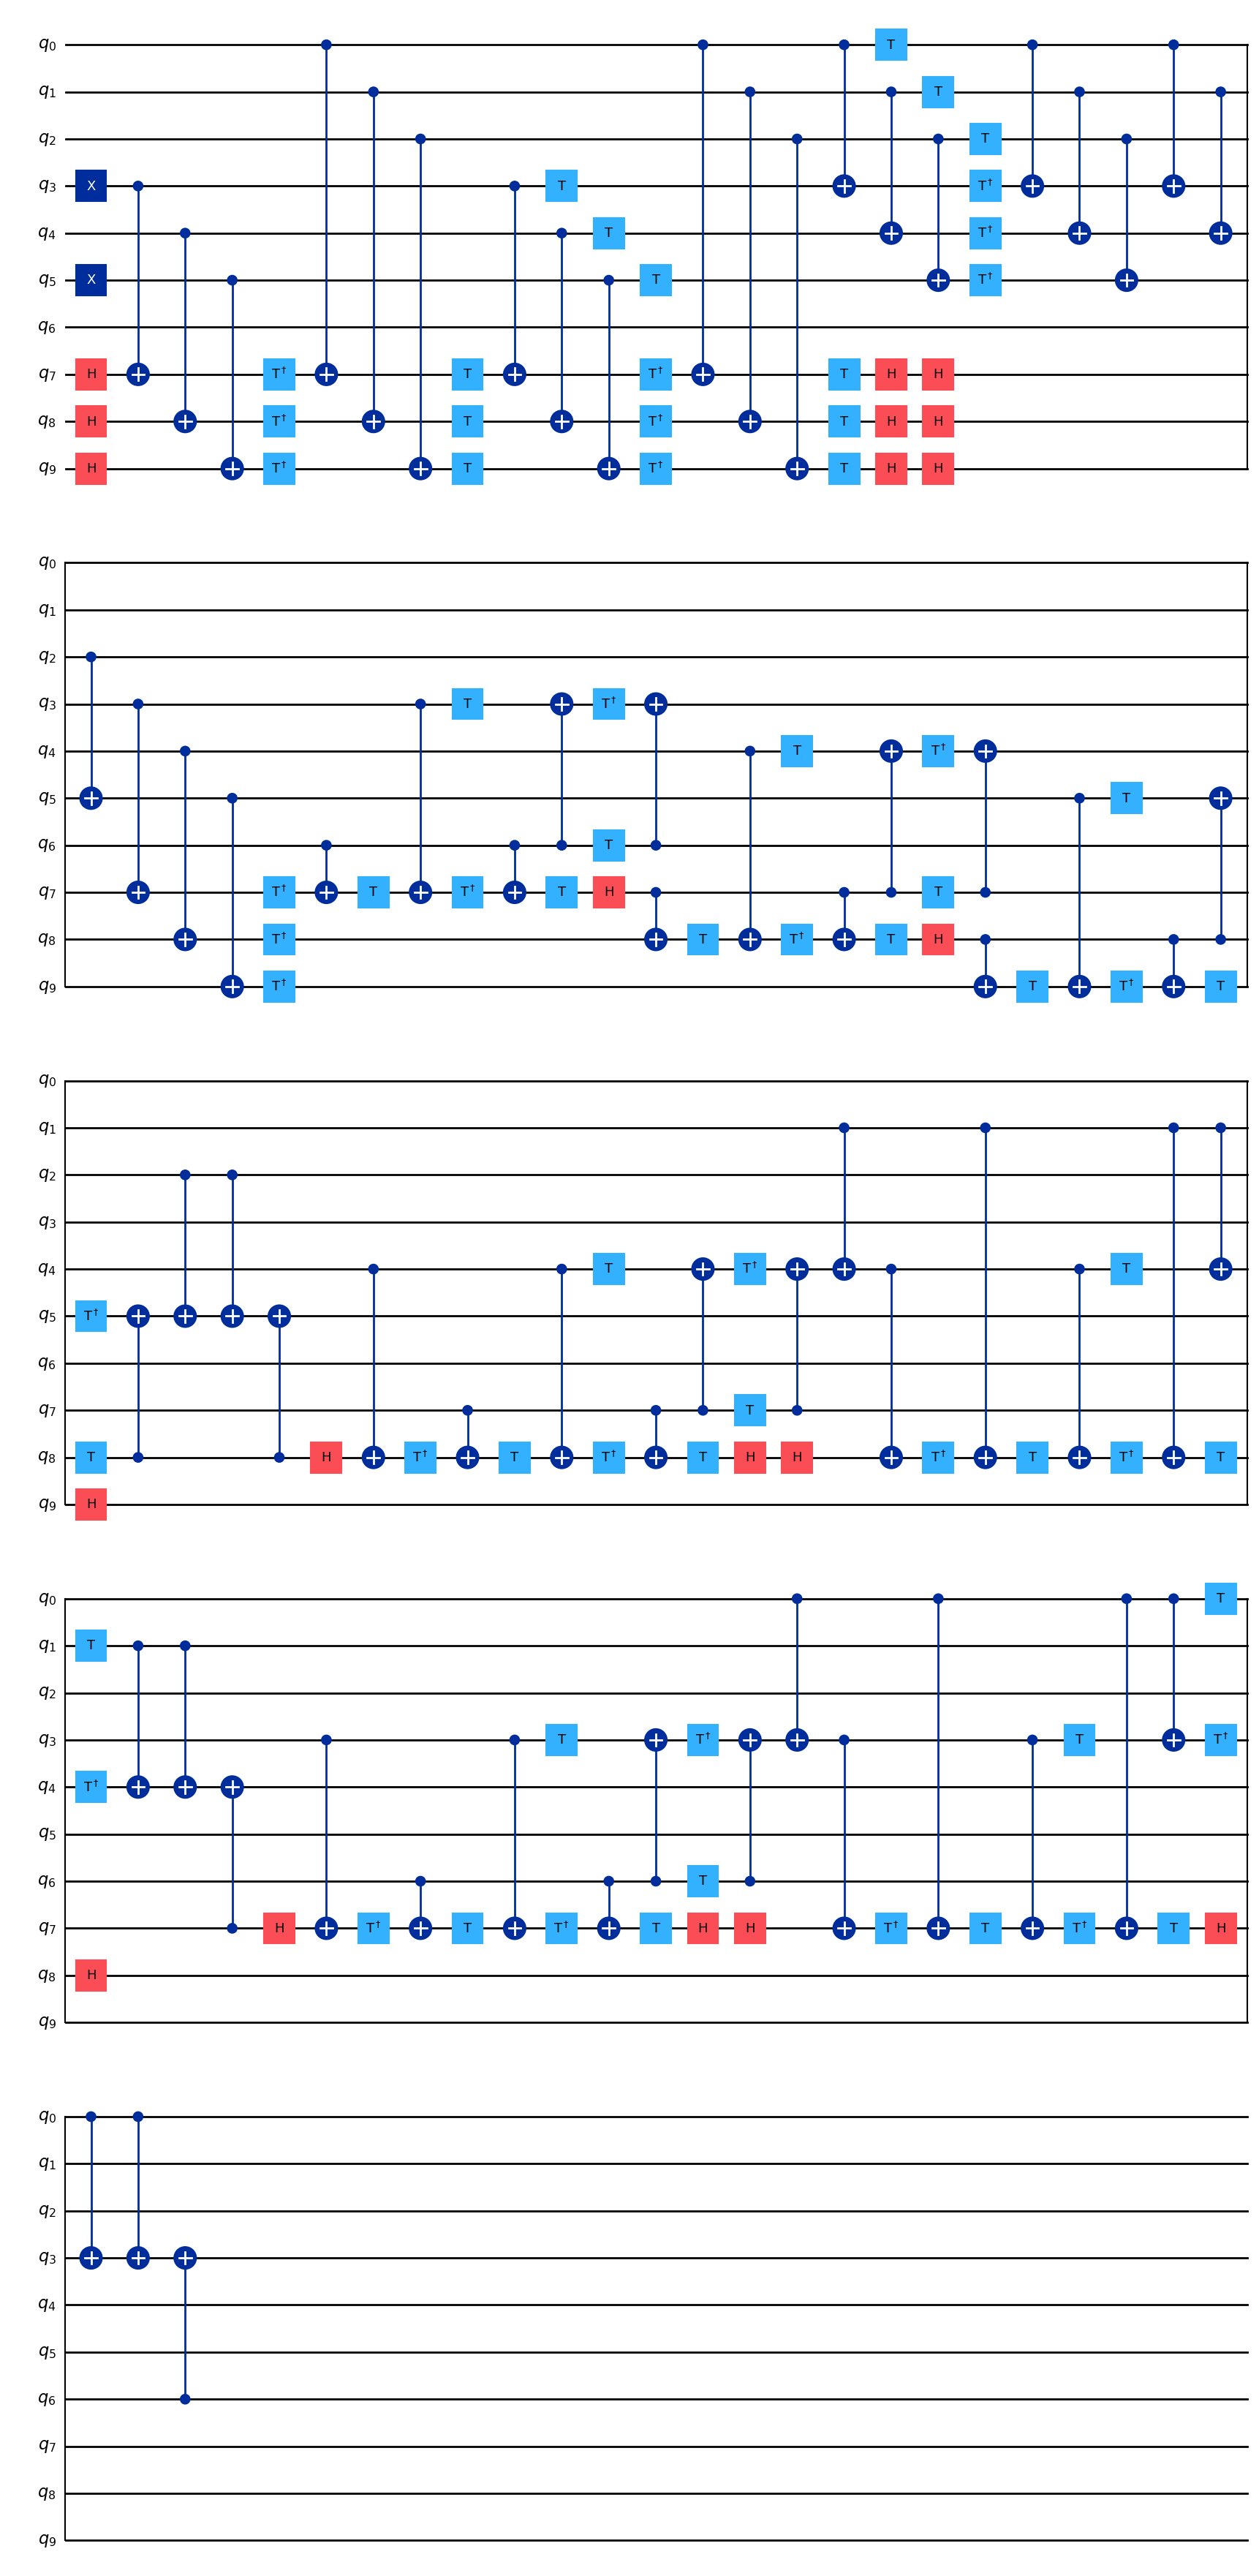

Aggressive (full_reduce) circuit:


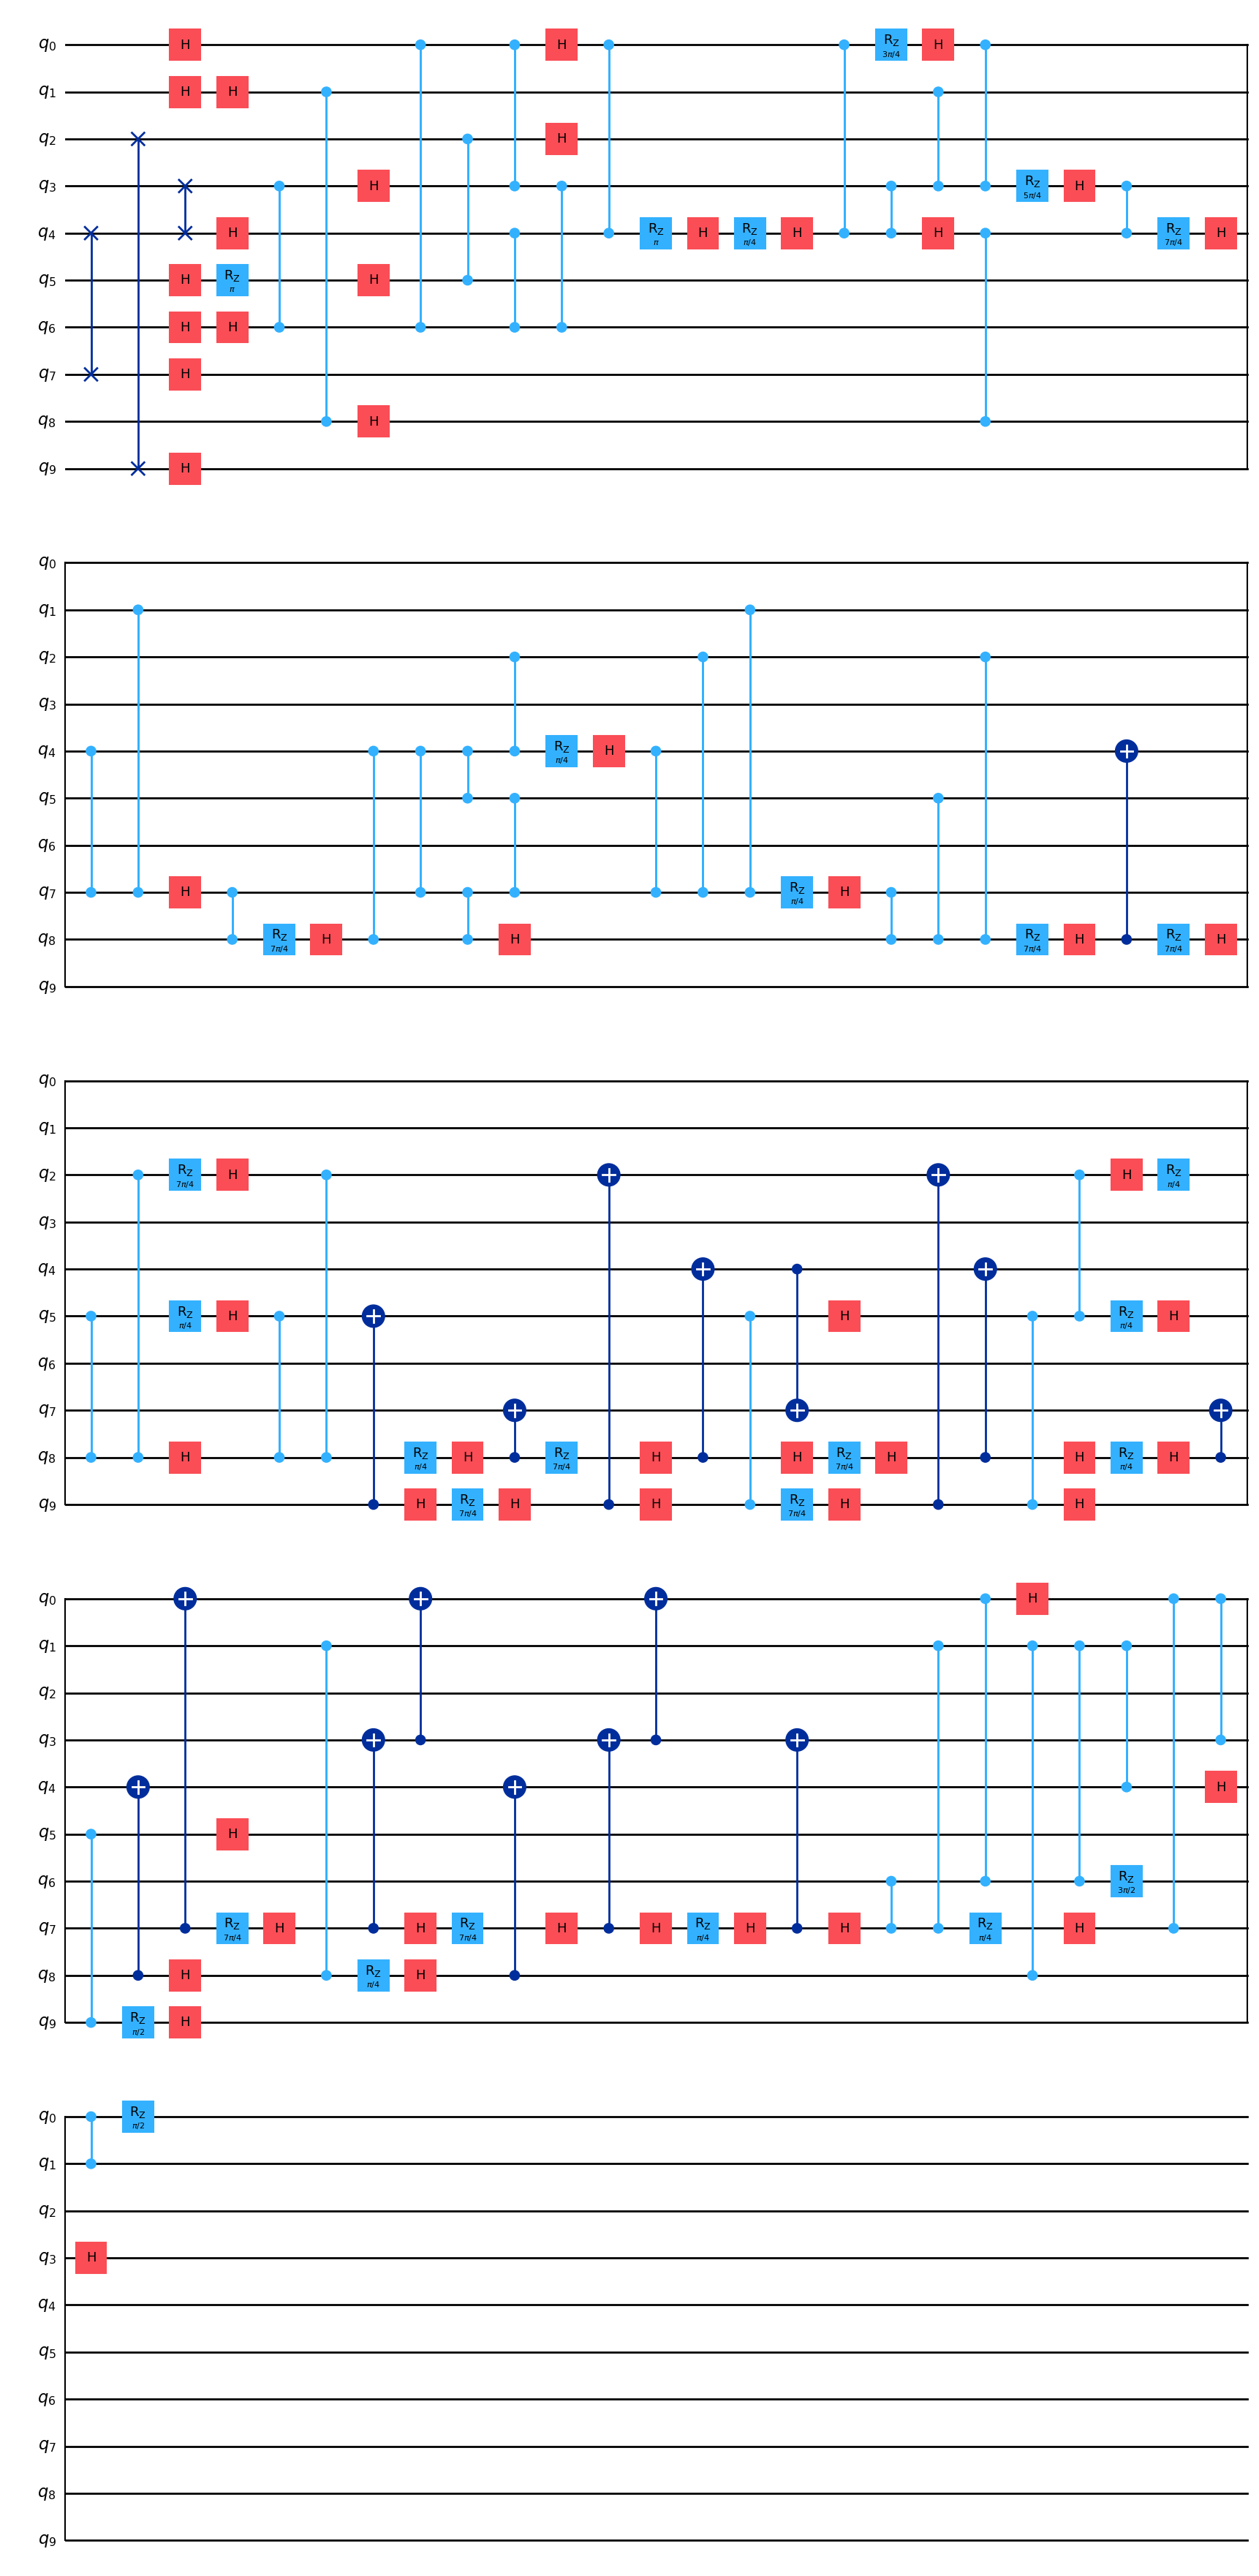

In [13]:
print("Baseline circuit:")
display(qc_baseline.draw("mpl"))

print("Careful (teleport_reduce) circuit:")
display(qc_careful.draw("mpl"))

print("Aggressive (full_reduce) circuit:")
display(qc_aggressive.draw("mpl"))

## 9. Comparison graphs: real vs. fake, across Total Gates, Two-Qubit Gates, T-Count, and Depth\n\nSame colorful bar-graph structure as the original pre-flight comparison, now split side-by-side for fake vs. real so both are visible in one figure — useful for a clean GitHub write-up.

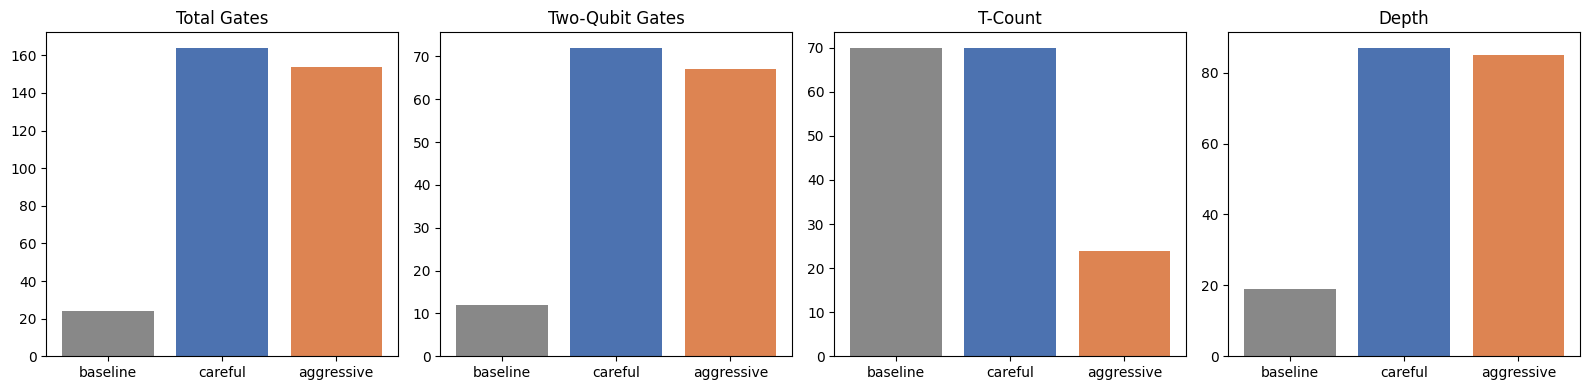

In [14]:
_names = list(versions.keys())
_metrics_list = [circuit_metrics(versions[n]) for n in _names]

fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, key, title in zip(
    axes,
    ["total_gates", "two_qubit_gates", "tcount", "depth"],
    ["Total Gates", "Two-Qubit Gates", "T-Count", "Depth"],
):
    values = [m[key] for m in _metrics_list]
    ax.bar(_names, values, color=["#888888", "#4C72B0", "#DD8452"])
    ax.set_title(title)
plt.tight_layout()
plt.show()

## Why did we see that?

---

| Method | What it optimizes for | Effect on my circuit | Why |
|---|---|---|---|
| **`full_reduce`** | spider count / T-count | ~3x gate blowup | Destroys the geometric locality my CNOT-cheapness depended on;<br>extraction (Gaussian elimination) pays for the added entanglement in CNOTs |
| **`teleport_reduce`** | merging matching phase gates only | no change vs. baseline | My circuit has no repeated matching phase angles for it to merge |

## 10. New accuracy metric: magnetization vs. exact answer

The old "all-zeros" accuracy mixed real physics with hardware noise: the transverse field is *supposed* to rotate qubits away from 0, so even a perfect machine would not score 100%.

- **Measured magnetization:** for each shot, a qubit measured as 0 counts +1 and a qubit measured as 1 counts -1. Average over all qubits and shots.
- **Exact magnetization:** the same quantity from a noiseless statevector simulation (the answer key).
- **Error = |measured - exact|.** Lower is better.

In [15]:
def measured_magnetization(counts, num_qubits):
    """Mean <Z> over all qubits, straight from measured counts.
    +1 for each '0' bit, -1 for each '1' bit, averaged over qubits and shots."""
    shots = sum(counts.values())
    total = 0.0
    for bitstring, c in counts.items():
        bits = bitstring.replace(" ", "")[-num_qubits:]
        total += sum(1 if b == "0" else -1 for b in bits) * c
    return total / (shots * num_qubits)

In [16]:
from qiskit.quantum_info import Statevector, SparsePauliOp

def exact_magnetization(circuit_no_measure, num_qubits):
    """Mean <Z> over all qubits from the noiseless statevector (the answer key).
    Pass a circuit with NO measurement instructions."""
    sv = Statevector.from_instruction(circuit_no_measure)
    vals = []
    for i in range(num_qubits):
        label = "I"*(num_qubits-1-i) + "Z" + "I"*i
        vals.append(sv.expectation_value(SparsePauliOp(label)).real)
    return sum(vals) / num_qubits

### 10a. Scoring the 4-qubit runs (fake vs. real)

Rescores the counts already collected, so no new hardware runs. All three circuit versions are equivalent, so they share one exact answer.

10 qubits | exact magnetization (answer key) = 0.6000

baseline   fake: measured=0.5501 err=0.0499
careful    fake: measured=0.5430 err=0.0570
aggressive fake: measured=0.4924 err=0.1076


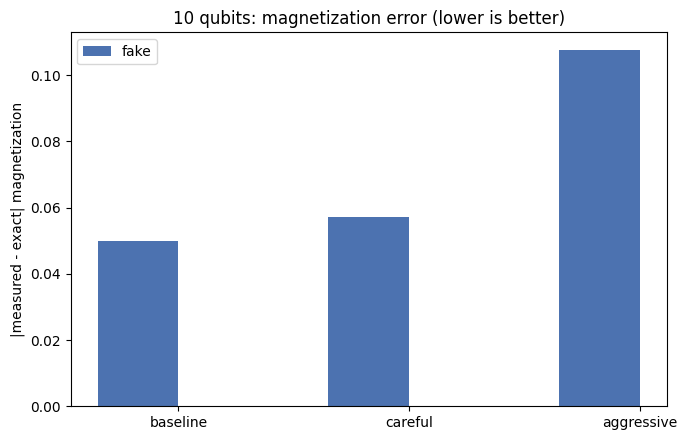

In [17]:
nq_base = qc_baseline.num_qubits       # adder uses 3n+1 qubits (10 for the 3-bit example)
exact_base = exact_magnetization(qc_baseline.remove_final_measurements(inplace=False), nq_base)
print(f"{nq_base} qubits | exact magnetization (answer key) = {exact_base:.4f}\n")

fake_err_b, real_err_b = [], []
for name in versions:
    m_fake = measured_magnetization(fake_results[name]["counts"], nq_base)
    fake_err_b.append(abs(m_fake - exact_base))
    line = f"{name:10s} fake: measured={m_fake:.4f} err={fake_err_b[-1]:.4f}"
    if real_results is not None:
        m_real = measured_magnetization(real_results[name]["counts"], nq_base)
        real_err_b.append(abs(m_real - exact_base))
        line += f" | real: measured={m_real:.4f} err={real_err_b[-1]:.4f}"
    print(line)

x = np.arange(len(versions))
width = 0.35
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(x - width / 2, fake_err_b, width, label="fake", color="#4C72B0")
if real_results is not None:
    ax.bar(x + width / 2, real_err_b, width, label="real", color="#DD8452")
ax.set_xticks(x)
ax.set_xticklabels(list(versions.keys()))
ax.set_ylabel("|measured - exact| magnetization")
ax.set_title(f"{nq_base} qubits: magnetization error (lower is better)")
ax.legend()
plt.tight_layout()
plt.show()

## 11. Magnetization error vs. number of qubits

Repeats the comparison for larger circuits (fake backend only; set `RUN_REAL = True` to also run on real hardware, which uses IBM time). Fake runs are repeated `FAKE_REPS` times, so the plot shows mean ± standard deviation.

In [ ]:
QUBIT_COUNTS = [5, 10, 15, 20]   # targets; the adder uses 3n+1 qubits, so each is rounded
FAKE_REPS = 1                    # repeats on fake -> mean +/- std (free, but slow at 16-19 qubits)


def bits_for(target_qubits):
    """Adder bit-width n whose qubit count 3n+1 is closest to the target."""
    return max(1, round((target_qubits - 1) / 3))


def build_versions_for(n):
    """Adder of bit-width n: baseline + the two ZX-reduced versions (each equivalence-checked inside)."""
    a_str = ("011" * n)[:n]
    b_str = ("101" * n)[:n]          # n = 3 gives the original 011 + 101
    baseline = quantum_adder(a_str, b_str)
    careful = teleport_reduce_circuit(baseline)
    aggressive = full_reduce_circuit(baseline)
    return {"baseline": baseline, "careful": careful, "aggressive": aggressive}


summary = {}   # summary[actual_qubits][version] = {...}

for target in QUBIT_COUNTS:
    n = bits_for(target)
    tag = f"n{n}"
    versions_q = build_versions_for(n)
    nq = versions_q["baseline"].num_qubits
    print(f"\n=== target {target} -> {n}-bit adder = {nq} qubits ===")

    # the three versions are verified equal, so they share ONE answer key
    exact = exact_magnetization(versions_q["baseline"].remove_final_measurements(inplace=False), nq)
    print(f"exact magnetization (answer key) = {exact:.4f}")
    summary[nq] = {}

    fake_meas = {v: [] for v in versions_q}
    fake_errs = {v: [] for v in versions_q}
    for _ in range(FAKE_REPS):
        res = run_versions_on_backend(versions_q, FakeKingston(), shots=shots_per_run)
        for v in versions_q:
            m = measured_magnetization(res[v]["counts"], nq)
            fake_meas[v].append(m)
            fake_errs[v].append(abs(m - exact))

    real_res = get_real_results(versions_q, tag)    # None when REAL_MODE == "off"

    for v in versions_q:
        s = {
            "fake_err": float(np.mean(fake_errs[v])),
            "fake_std": float(np.std(fake_errs[v])),
            "real_err": None,
        }
        line = (f"{v:10s} fake: measured={np.mean(fake_meas[v]):.4f} "
                f"error={s['fake_err']:.4f} +/- {s['fake_std']:.4f}")
        if real_res is not None:
            m_real = measured_magnetization(real_res[v]["counts"], nq)
            s["real_err"] = abs(m_real - exact)
            line += f" | real: measured={m_real:.4f} error={s['real_err']:.4f}"
        summary[nq][v] = s
        print(line)

# error vs. number of qubits
sizes = sorted(summary)
fig, ax = plt.subplots(figsize=(7, 4))
for v in ["baseline", "careful", "aggressive"]:
    ax.errorbar(sizes,
                [summary[q][v]["fake_err"] for q in sizes],
                yerr=[summary[q][v]["fake_std"] for q in sizes],
                marker="o", capsize=3, label=f"{v} (fake)")
    real_pts = [(q, summary[q][v]["real_err"]) for q in sizes if summary[q][v]["real_err"] is not None]
    if real_pts:
        ax.plot([p[0] for p in real_pts], [p[1] for p in real_pts],
                marker="s", linestyle="--", label=f"{v} (real)")
ax.set_xlabel("Number of qubits (3n + 1)")
ax.set_ylabel("|measured - exact| magnetization")
ax.set_title("Magnetization error vs. qubit count (lower is better)")
ax.legend()
plt.tight_layout()
plt.show()


=== target 5 -> 1-bit adder = 4 qubits ===
exact magnetization (answer key) = 0.5000
baseline   fake: measured=0.4993 error=0.0007 +/- 0.0000
careful    fake: measured=0.4904 error=0.0096 +/- 0.0000
aggressive fake: measured=0.4407 error=0.0593 +/- 0.0000

=== target 10 -> 3-bit adder = 10 qubits ===
exact magnetization (answer key) = 0.4000
baseline   fake: measured=0.3296 error=0.0704 +/- 0.0000
careful    fake: measured=0.3321 error=0.0680 +/- 0.0000
aggressive fake: measured=0.3271 error=0.0729 +/- 0.0000

=== target 15 -> 5-bit adder = 16 qubits ===
exact magnetization (answer key) = 0.2500


### Results

- `baseline` and `careful` (teleport_reduce) give the same magnetization error within error bars, since teleport_reduce found nothing to merge in this circuit.
- `aggressive` (full_reduce) is noticeably worse, and the gap grows with qubit count (about 0.19 at 5 qubits and 0.60 at 10 on the fake backend). This is consistent with its roughly 3x gate count.
- Unlike the old all-zeros metric, this error does not collapse simply because there are more qubits.
- Caveat: these are noise-model (FakeKingston) results for this specific circuit; real-hardware results at these sizes have not been run.